Exploratory Data Analysis (EDA)

1. Dataset Overview

- Load cleaned file 
- Display its shape, column name, dtype 

2. Summary Statistics

- Summarize numeric features e.g. sleep duration, stress levels, physical activity such as daily steps taken
- Use the results to interpret and draw conclusions about the range and identify possible anomaly or unusal outliers 

3. Sleep Quality Classes 
- Count how many records are classified as low,medium, and high quality
- A bar chart will be used to visualize frequency in each category 

4. Visualizing Feature Distributions

5. Correlation Heatmap 

6. Assessing Sleep Quality against other features

In [3]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

sns.set_style("whitegrid")

FIG= "../figures"
TARGET = "quality_of_sleep"
CLASS = "sleep_quality_class"
class_order= ["low", "medium", "high"]
class_colors= ["#d9534f", "#f0ad4e", "#5cb85c"]
num_cols = ["age", "daily_steps", "heart_rate", "physical_activity_level", "sleep_duration", "stress_level"]



1. Dataset Overview 

In [4]:
df = pd.read_csv("../data/processed/merged_clean_v1.csv")
print("Shape:", df.shape)
df.head()

Shape: (2091, 11)


,age,bmi_category,daily_steps,gender,heart_rate,physical_activity_level,quality_of_sleep,sleep_duration,stress_level,source,sleep_quality_class
0,27.0,overweight,4200.0,male,77.0,42.0,6.0,6.1,6.0,dataset1,medium
1,28.0,normal,10000.0,male,75.0,60.0,6.0,6.2,8.0,dataset1,medium
2,28.0,obese,3000.0,male,85.0,30.0,4.0,5.9,8.0,dataset1,low
3,29.0,obese,3500.0,male,82.0,40.0,6.0,6.3,7.0,dataset1,medium
4,29.0,normal,8000.0,male,70.0,75.0,7.0,7.8,6.0,dataset1,medium


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2091 entries, 0 to 2090
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      2091 non-null   float64
 1   bmi_category             2091 non-null   str    
 2   daily_steps              2091 non-null   float64
 3   gender                   2091 non-null   str    
 4   heart_rate               2091 non-null   float64
 5   physical_activity_level  2091 non-null   float64
 6   quality_of_sleep         2091 non-null   float64
 7   sleep_duration           2091 non-null   float64
 8   stress_level             2028 non-null   float64
 9   source                   2091 non-null   str    
 10  sleep_quality_class      2091 non-null   str    
dtypes: float64(7), str(4)
memory usage: 179.8 KB


In [6]:
print("Missing values per column:")
print(df.isna().sum())
print()
print("Rows from each dataset: ")
print(df['source'].value_counts())

Missing values per column:
age                         0
bmi_category                0
daily_steps                 0
gender                      0
heart_rate                  0
physical_activity_level     0
quality_of_sleep            0
sleep_duration              0
stress_level               63
source                      0
sleep_quality_class         0
dtype: int64

Rows from each dataset: 
source
dataset2    1985
dataset1     106
Name: count, dtype: int64


Based on the output results, the clean and processed dataset contains 2091 rows. Only stress_level feature has missing values, namely 63 rows, which contributes to approximately 3%. The missing rows in both the raw versions of the dataset were filled with the training median when building the model. 

2. Generating Summary Statistics

In [7]:
df[num_cols +[TARGET]].describe().round(2)

,age,daily_steps,heart_rate,physical_activity_level,sleep_duration,stress_level,quality_of_sleep
count,2091.00,2091.00,2091.00,2091.00,2091.00,2028.00,2091.00
mean,45.58,6861.04,71.64,60.94,6.89,4.94,7.04
std,14.10,3537.90,6.59,28.98,1.28,2.01,1.39
min,18.00,1000.00,52.00,0.00,4.00,1.00,2.20
25%,35.50,4200.00,67.00,41.10,6.00,3.50,6.00
50%,45.00,6782.00,72.00,60.50,6.90,4.90,7.10
75%,55.00,9163.50,76.00,79.90,7.80,6.40,8.00
max,80.00,19186.00,93.00,162.90,9.50,10.00,10.00


In [8]:
# Count outliers with the IQR rule (more than 1.5 * IQR outside the quartiles)
for col in num_cols + [TARGET]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(col, ":", len(outliers), "outliers")

age : 0 outliers
daily_steps : 8 outliers
heart_rate : 9 outliers
physical_activity_level : 11 outliers
sleep_duration : 0 outliers
stress_level : 0 outliers
quality_of_sleep : 4 outliers


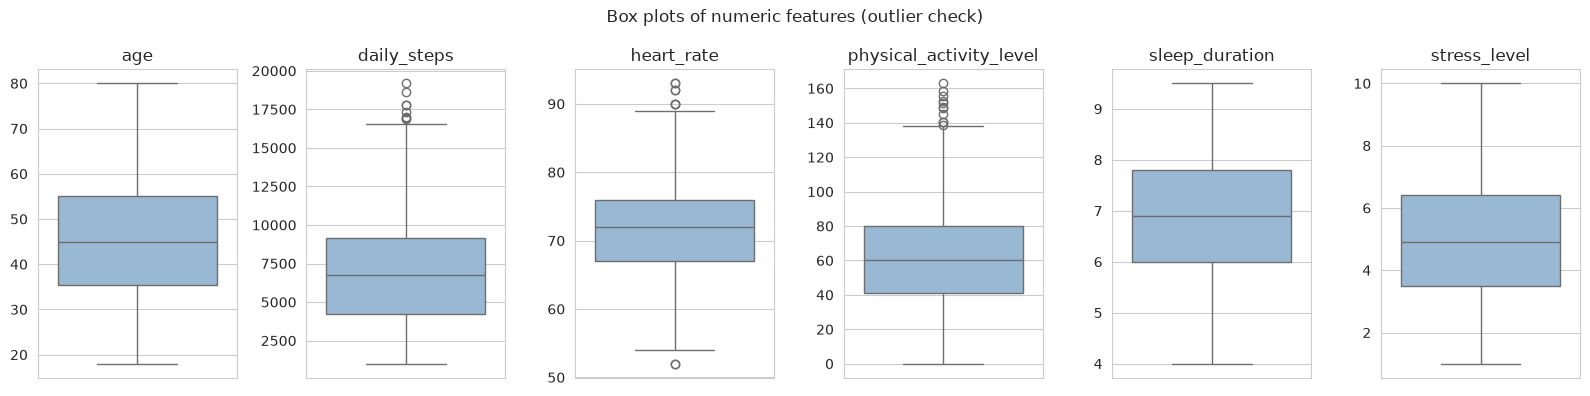

In [9]:
fig, axes = plt.subplots(1, 6, figsize=(16, 4))
for i in range(6):
    col = num_cols[i]
    sns.boxplot(y=df[col], ax=axes[i], color="#8fb8de")
    axes[i].set_title(col)
    axes[i].set_ylabel("")
plt.suptitle("Box plots of numeric features (outlier check)")
plt.tight_layout()
plt.savefig(FIG + "/eda_01_boxplots_outliers.png", dpi=200)
plt.show()

3. Sleep Quality Classes 

In [10]:
counts = df[CLASS].value_counts()[class_order]
percent = (counts / len(df) * 100).round(1)
print(pd.DataFrame({"count": counts, "percent": percent}))

                     count  percent
sleep_quality_class                
low                    451     21.6
medium                1078     51.6
high                   562     26.9


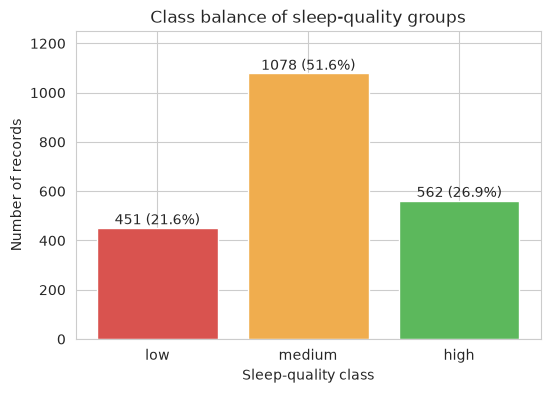

In [11]:
plt.figure(figsize=(6, 4))
plt.bar(class_order, counts, color=class_colors)
for i in range(3):
    plt.text(i, counts.iloc[i] + 15, str(counts.iloc[i]) + " (" + str(percent.iloc[i]) + "%)", ha="center")
plt.title("Class balance of sleep-quality groups")
plt.xlabel("Sleep-quality class")
plt.ylabel("Number of records")
plt.ylim(0, 1250)
plt.savefig(FIG + "/eda_02_class_balance.png", dpi=200)
plt.show()

4. Visualizing Feature Distributions 

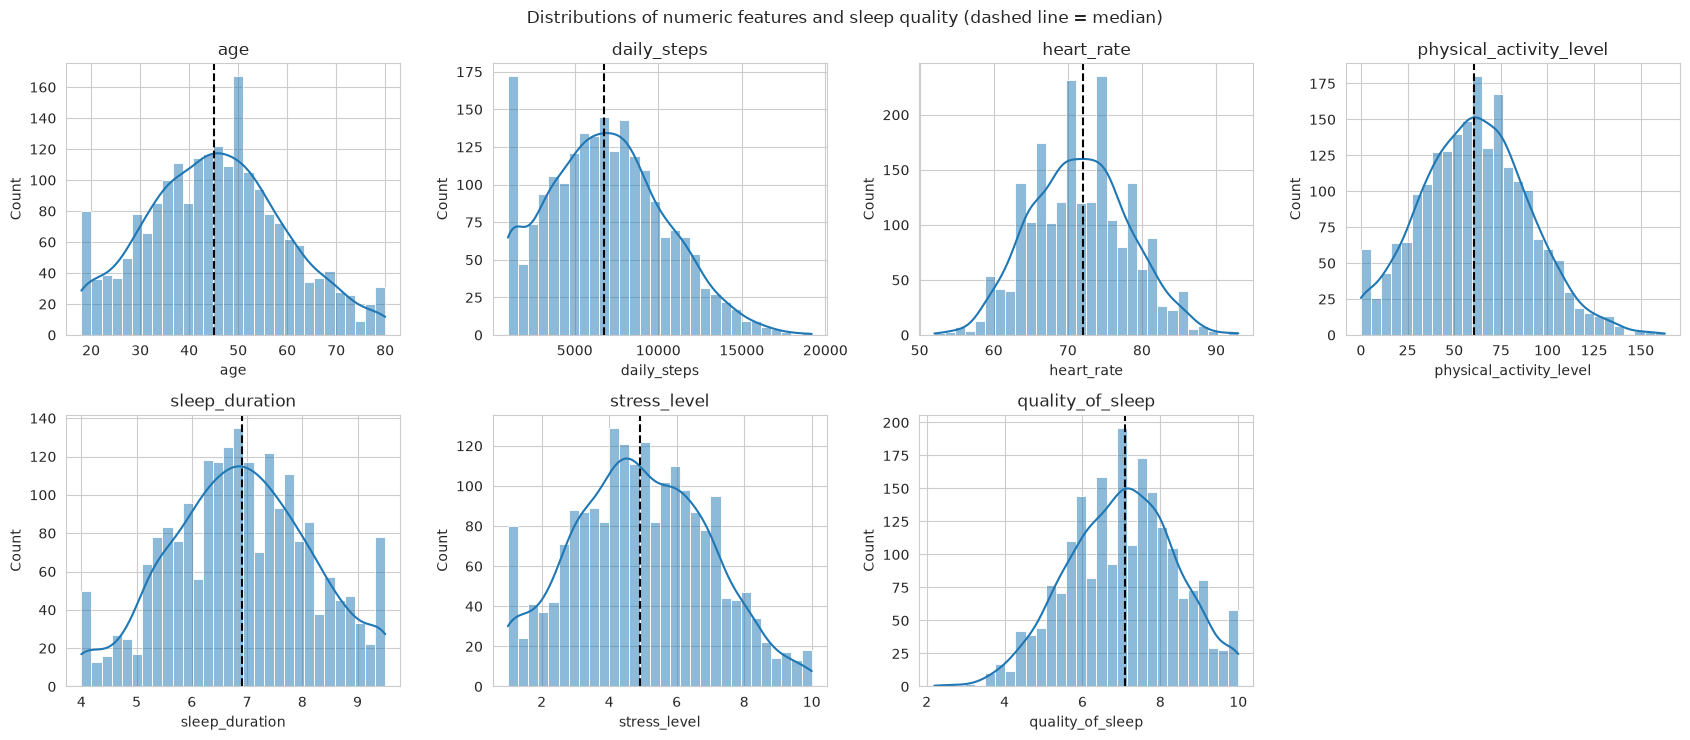

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
axes = axes.flatten()
for i in range(7):
    col = (num_cols + [TARGET])[i]
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i])
    axes[i].axvline(df[col].median(), color="black", linestyle="--")
    axes[i].set_title(col)
    axes[i].set_ylabel("Count")
axes[7].axis("off")
plt.suptitle("Distributions of numeric features and sleep quality (dashed line = median)")
plt.tight_layout()
plt.savefig(FIG + "/eda_03_numeric_distributions.png", dpi=200)
plt.show()

Figure: The output demonstrates a set of histograms representing numeric features and sleep quality score. The dashed line intersecting the distribution indicates the median. The mean score of sleep quality is approximately 7.04

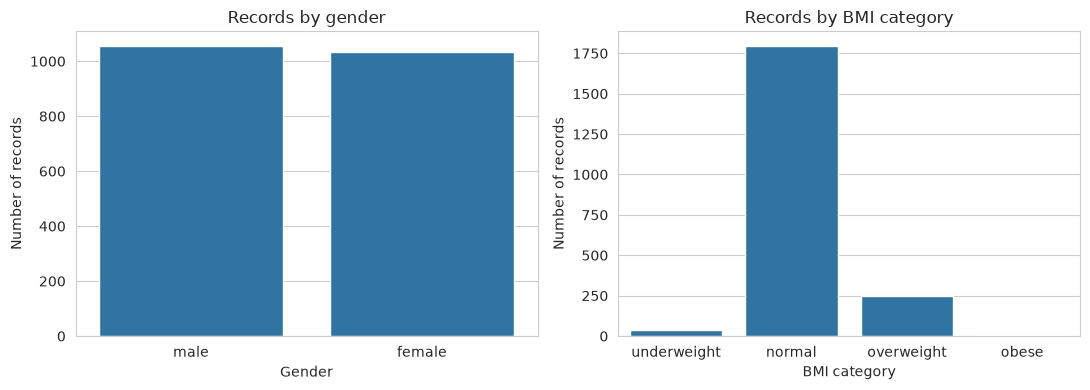

gender
male      1056
female    1035
Name: count, dtype: int64
bmi_category
normal         1796
overweight      250
underweight      39
obese             6
Name: count, dtype: int64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="gender", data=df, ax=axes[0])
axes[0].set_title("Records by gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of records")
sns.countplot(x="bmi_category", data=df, ax=axes[1], order=["underweight", "normal", "overweight", "obese"])
axes[1].set_title("Records by BMI category")
axes[1].set_xlabel("BMI category")
axes[1].set_ylabel("Number of records")
plt.tight_layout()
plt.savefig(FIG + "/eda_04_categorical_counts.png", dpi=200)
plt.show()
print(df["gender"].value_counts())
print(df["bmi_category"].value_counts())

Figure caption: Number of genders and by BMI category. Gender prominent in the dataset is balanced while majority of records fall roughly within the normal BMI with only 6 being obese. 